# Regex and Pandas

How to make dataframes in python and also how to search through strings for the information you are looking for. Now we are starting the notebooks that are less about things you would typically find in an intro python class and more directly focused towards our scrapers and work with Inclusive Development International. 

## Dataframes in Python

Unlike R, Julia, and some other languages that were written specifically for data analysis, Python does not have a built in dataframe structure. Lucky for us, some other people wrote code to make dataframes and shared it with the world in a package called `Pandas`. 

A package is a collection of python files that people write, bundle, and publish for sharing. If the authors follow certain protocols and rules for accessibility, testing, and documentation, they can publish it in the python package manager `pip`, the main installer for paython packages. 

`pip` comes installed whenever you install python, so to access it, most of you will open a terminal (the one inside VSCode is okay or on your computer either way) and just type `pip`. It should pop up with a list of a bunch of commands you can use. 

We need to install Pandas. In your terminal, type `pip install pandas` 

Now that Pandas is installed, we need to tell Python that we'd like to use it, which we do by including the following code. `import pandas` does exactly that and the `as pd` part says that in order to access a pandas command, I only have to use `pd` instead of typing out `pandas`.

In [3]:
import pandas as pd

Let's make a basic dataframe

In [4]:
data = pd.DataFrame()

In [5]:
data #this is an empty dataframe

""


We will go over two types of inputs that you can use to make a dataframe. One way that is internal to Python is that you can turn a dictionary into a dataframe. Here's a dictionary.

In [6]:
info = {0: {"First Name": "Christopher", "Last Name": "Potvin", "Email": "cpotvin@warren-wilson.edu", "Phone": 8284854253}}

In [7]:
df = pd.DataFrame(info)

df

,0
First Name,Christopher
Last Name,Potvin
Email,cpotvin@warren-wilson.edu
Phone,8284854253


I probably want to switch the rows and columns from what I just did - the best way to do this is to take the transpose of the dataframe with `df.T`

**Exercise 1** In a code cell below, use `df.T` to make the dataframe only have one row. Did this actually modify `df` or just compute the transpose in live memory?

In [8]:
df_transposed = df.T
df_transposed
df = df.T
df

,First Name,Last Name,Email,Phone
0,Christopher,Potvin,cpotvin@warren-wilson.edu,8284854253


So, by default, when you load a dictionary in as a dataframe, each key in the dictionary becomes a column in the dataframe.

**Exercise 2:** Make a dictionary with the keys "First Name", "Last Name" and "Email" and then have each value be a list of three things that make sense. Make a dataframe out of that dictionary. 

In [9]:


people = {
    "First Name": ["Jahmari", "Jaime", "Stevie"],
    "Last Name": ["Hutchinson", "Millan", "moodie"],
    "Email": ["jahmari.hutchinson@example.com", "jaime.millan@example.com", "stevie.moodie@example.com"]
}

df = pd.DataFrame(people)
df

,First Name,Last Name,Email
0,Jahmari,Hutchinson,jahmari.hutchinson@example.com
1,Jaime,Millan,jaime.millan@example.com
2,Stevie,moodie,stevie.moodie@example.com


Of course, if you have a spreadsheet of data you want to use, you don't need to type it all into python manually.

**Exercise 3:** Download the csv file from moodle, and then the below code should load it in after you make sure to put it in the same folder as this file. 

In [10]:
data = pd.read_csv("ashevilleairport.csv")


In [11]:
data

,DATE,PRCP,TMAX,TMIN,WSF2,WSF5,AWND
0,1/1/2000,0.0,64,31,19.9,21.9,4.47
1,1/2/2000,0.0,67,48,21.0,23.9,8.72
2,1/3/2000,0.0,63,55,19.9,29.1,9.17
3,1/4/2000,0.2,62,35,25.1,30.0,12.75
4,1/5/2000,0.0,42,25,25.1,32.0,8.95
...,...,...,...,...,...,...,...
8761,12/27/2023,0.0,61,43,12.1,19.0,2.91
8762,12/28/2023,0.0,53,33,15.0,23.0,5.82
8763,12/29/2023,0.0,41,31,21.0,40.9,8.72
8764,12/30/2023,0.0,44,32,13.0,17.0,6.93


In [22]:
data["DATE"] #This is how you access one column of a dataset in python

0         1/1/2000
1         1/2/2000
2         1/3/2000
3         1/4/2000
4         1/5/2000
           ...    
8761    12/27/2023
8762    12/28/2023
8763    12/29/2023
8764    12/30/2023
8765    12/31/2023
Name: DATE, Length: 8766, dtype: str

Now you could do anything we do in Applied Stats or Intro to Data Science in Python as well, although you probably need other packages. For example, 

In [13]:
max(data['TMAX']) #98 degrees is the highest max temperature in this dataset. 

98

<Axes: >

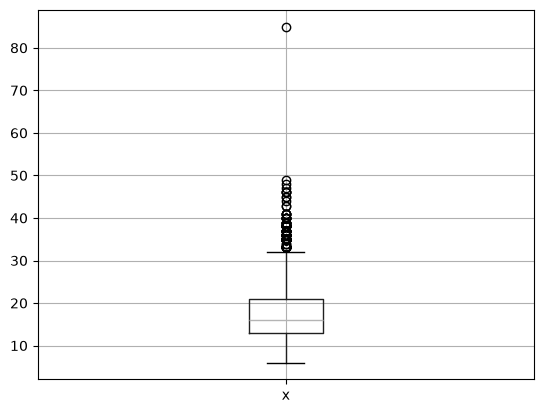

In [14]:
pd.plotting.boxplot(data['WSF2']) #phew this built in boxplot function is ugly

For the purposes of our class, though, we don't need to do any statistics with our dataframes. But we do have to make them. We will be taking data off of pdfs or maybe the raw html of a website, and we have to turn that information into a spreadsheet. Even for a table off of a pdf, computers can't directly read the tabular information off of them because of the way they are encoded. 

So what we have to do is take the text off of a pdf, read it into Python as a big string, and separate it into the table ourselves. 

## Regular Expressions

We use regular expressions to do this. Regular expressions are stringlike patterns that you use to find types of words or characters in text. 

In [15]:
message = "For example, here is a string with a lot of text. I might have loaded it in from a pdf or maybe I am reading the html off of a website, but no matter how I got it, most of the text probably really isn't that important. But some parts of the string are important, like the fact that you can reach me at cpotvin@warren-wilson.edu if you need to reach me. If for some reason, I am not responding and it is an emergency, you could contact my department chair Holly instead at hrosson@warren-wilson.edu. However, if you have questions about housing, we are probably not the right people to ask and instead you would want to contact housing@warren-wilson.edu. Make sure not to click on any links that don't come from the domain warren-wilson.edu as they are likely spam. After you graduate, you might want to contact me via my personal emails redsoxfan1994@hotmail.com or princeraspberryb3r3t@aol.com. Those are made up don't worry."
message

"For example, here is a string with a lot of text. I might have loaded it in from a pdf or maybe I am reading the html off of a website, but no matter how I got it, most of the text probably really isn't that important. But some parts of the string are important, like the fact that you can reach me at cpotvin@warren-wilson.edu if you need to reach me. If for some reason, I am not responding and it is an emergency, you could contact my department chair Holly instead at hrosson@warren-wilson.edu. However, if you have questions about housing, we are probably not the right people to ask and instead you would want to contact housing@warren-wilson.edu. Make sure not to click on any links that don't come from the domain warren-wilson.edu as they are likely spam. After you graduate, you might want to contact me via my personal emails redsoxfan1994@hotmail.com or princeraspberryb3r3t@aol.com. Those are made up don't worry."

I'd like to get all of the emails that are in `message`. 

**Exercise 4:** Can you describe to me the general format of a string of characters that looks like an email? I know this is insultingly easy, but when your patterns are more difficult, you'll want to be in the practice of doing this. 

In [ ]:
#Exercise 4:
r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
# Regular expression to match email addresses
#the r before the string indicates that it is a raw string, which is useful for regular expressions in Python.

'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\\.[A-Za-z]{2,}'

Okay, so now we build the regular expression that we think is going to match what are looking for. 

The best documentation (in my humble opinion) is the official one: [re - Regular expression operations](https://docs.python.org/3/library/re.html)

Some past members of the scraping squad have also found this [site](https://regexr.com/) helpful. 

In [29]:
import re #You need to import the regular expression package, you don't need to install it, it comes with python

In [1]:
pattern = r"\S+?@.+?\.[a-z]+"
# We put r before the string to indicate that it is a regular expression string

In [31]:
matches = re.findall(pattern, message)
matches
# We want to find all of the pattern inside of the message. 

['cpotvin@warren-wilson.edu',
 'hrosson@warren-wilson.edu',
 'housing@warren-wilson.edu',
 'redsoxfan1994@hotmail.com',
 'princeraspberryb3r3t@aol.com']

**Exercise 5** Let's go through this pattern to figure out what it is doing. Use the documentation link to suss out what the `\S` means. 

**Exercise 6** What about the `+?` What happens if you take the `?` off? 

I'll do the next part for you, the `@` tells us that we are indeed looking for an "@". 

**Exercise 7** After the `@`, we have `.+?` - what does that mean?

This is followed by `\.`. Since `.` usually means something else to regular expressions (see above), we have to use `\.` to say that we want an actual "." The "\\" in that part is referred to as an escape character. (If you look at my markdown code, you'll see I had to write \\ twice because markdown also uses \\ as an escape character usually.)

**Exercise 8** Lastly, what does the `[a-z]+` match?

**Exercise 9** Can you put that all together to explain how the pattern isolates and returns all of the emails?

In [ ]:
#Exercise 5:
#\S means any non-whitespace character in a regular expression. 
re.findall(r"\S", "hi @ yo")
re.findall(r"\S+", "hi @ yo")



['hi', '@', 'yo']

In [43]:
#Exercise 6: The '+' means “one or more” of the preceding character and adding '?' after makes it lazy, so it matches as few characters as possible instead of as many as possible.
t = "contact ann@site.org and bo@web.com today"
re.findall(r"\S+?@.+?\.[a-z]+", t)   
re.findall(r"\S+?@.+\.[a-z]+",  t)   

['ann@site.org and bo@web.com']

In [42]:
#Exercise 7: '.' matches any single character except a newline character. and +? means “one or more” of the preceding character, but as few as possible instead of as many as possible.
t = "contact ann@site.org and bo@web.com today"
re.findall(r".+?@.+?\.[a-z]+", t)   
re.findall(r".+?@.+\.[a-z]+",  t)   

['contact ann@site.org and bo@web.com']

In [ ]:
#Exercise 8: [a-z]+ matches one or more lowercase letters.
re.findall(r"[a-z]+", "Hello World")

['e', 'lo', 'orld']

In [53]:
#Exercise 9:
re.findall(r"\S+?@.+?\.[A-Z]+", "Write ANN@SITE.ORG or call 555.")


['ANN@SITE.ORG']

In [19]:
df2 = pd.DataFrame(matches) #And we can put it directly into a dataframe. 
df2

,0
0,cpotvin@warren-wilson.edu
1,hrosson@warren-wilson.edu
2,housing@warren-wilson.edu
3,redsoxfan1994@hotmail.com
4,princeraspberryb3r3t@aol.com


**Exercise 10** Pull all of the prices out of the following string. You'll need to escape the dollar sign, probably. And you can use `\d` to match digits. 

In [20]:
games = "Welcome to the Information Superhighway $29.95 \n Little Inferno: Ho Ho Holiday Edition $14.99 \n 7 Billion Humans $16.99 \n Human Resource Machine $9.99 \n Little Inferno $12.79 \n World of Goo $7.99 \n World of Goo 2 $29.99"

In [56]:
prices = re.findall(r"\$\d+\.\d{2}", games)
prices


['$29.95', '$14.99', '$16.99', '$9.99', '$12.79', '$7.99', '$29.99']

**Exercise 11** Turn the following string, which came from tabular data, into a pandas dataframe with name, email and phone columns. I know there are going to be some snags in this, but I'm not sure where they are yet. So I'll help as you get stuck. 

In [21]:
table  = " Christopher Potvin cpotvin@warren-wilson.edu 8284854253 Chris Potvin c3porobotman@gmail.com 8326442190 Lashawn Stark lalasta@hotmail.com 9807645723 Julie Broussard routinepoutine@cnet.ca 2309706746 Steve Irwin crochunter247365@sydcom.au 1876830065 Babe Ruth homerunking714@aol.com 7147147140 Smokey Bear blazeit420@onlyyou.net 4109083022 Rick Springfield jessie.my.girl.ily@netscape.org 4438675309"

In [57]:
names  = re.findall(r"[A-Z][a-z]+ [A-Z][a-z]+", table)
emails = re.findall(r"\S+@\S+", table)
phones = re.findall(r"\d{10}", table)

df = pd.DataFrame({"Name": names, "Email": emails, "Phone": phones})
df

,Name,Email,Phone
0,Christopher Potvin,cpotvin@warren-wilson.edu,8284854253
1,Chris Potvin,c3porobotman@gmail.com,8326442190
2,Lashawn Stark,lalasta@hotmail.com,9807645723
3,Julie Broussard,routinepoutine@cnet.ca,2309706746
4,Steve Irwin,crochunter247365@sydcom.au,1876830065
5,Babe Ruth,homerunking714@aol.com,7147147140
6,Smokey Bear,blazeit420@onlyyou.net,4109083022
7,Rick Springfield,jessie.my.girl.ily@netscape.org,4438675309


**Exercise 12 (Optional, but potentially very useful)** If you are really feeling spry, you could check out how to make groups with regular expressions, and do exercise 11 with only one pattern. You should be able to separate the names into first and last names if you do it this way too. This [website](https://www.tutorialsteacher.com/regex/grouping) offers a nice explanation in addition to the default documentation. 